In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("../data/industrial/metal.jpg")

if image is None:
    raise FileNotFoundError("Industrial image not found.")

rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

In [2]:
lower = np.array([5, 70, 40])
upper = np.array([25, 255, 255])

mask = cv2.inRange(hsv, lower, upper)

In [3]:
_, binary = cv2.threshold(
    mask,
    127,
    255,
    cv2.THRESH_BINARY
)

In [4]:
isolated = cv2.bitwise_and(
    image,
    image,
    mask=binary
)

isolated_rgb = cv2.cvtColor(
    isolated,
    cv2.COLOR_BGR2RGB
)

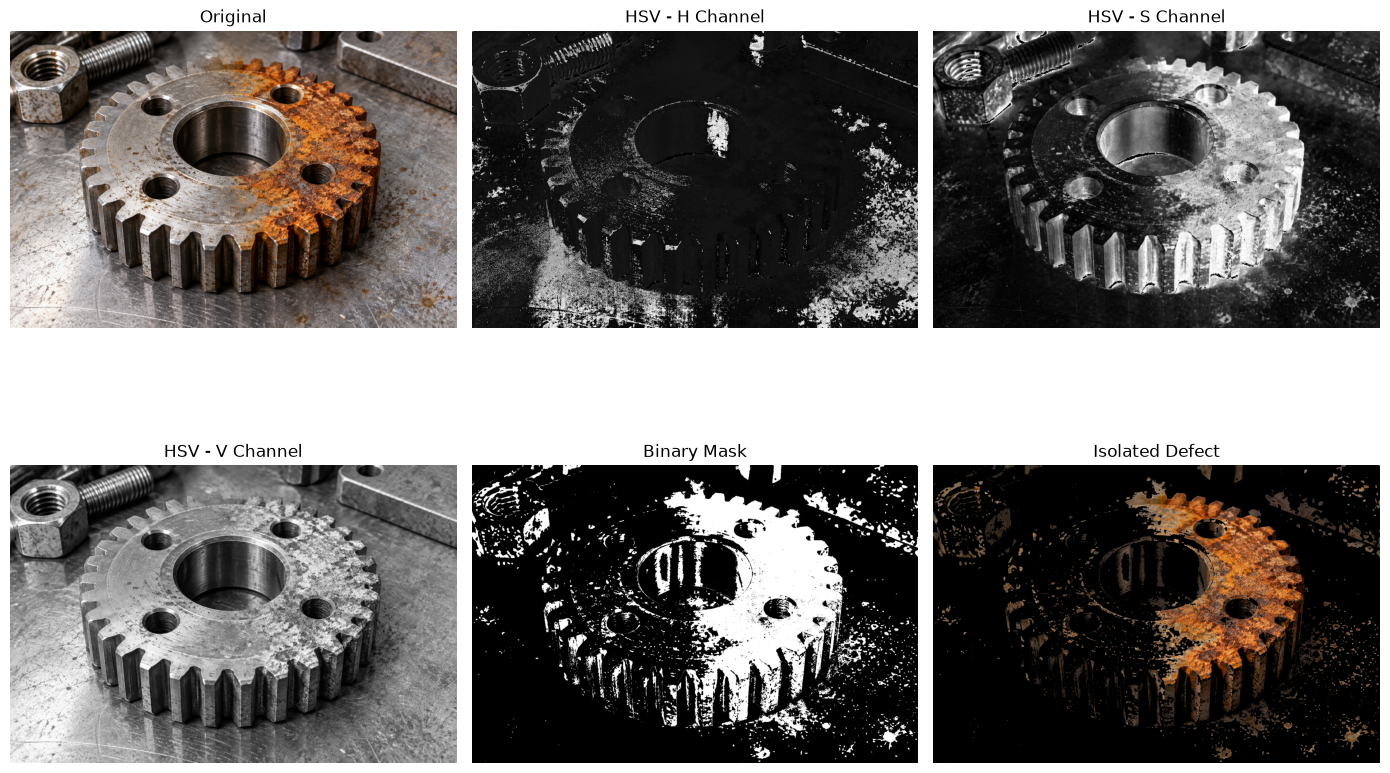

In [5]:
plt.figure(figsize=(14, 10))

plt.subplot(2, 3, 1)
plt.imshow(rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(hsv[:, :, 0], cmap="gray")
plt.title("HSV - H Channel")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(hsv[:, :, 1], cmap="gray")
plt.title("HSV - S Channel")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(hsv[:, :, 2], cmap="gray")
plt.title("HSV - V Channel")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(binary, cmap="gray")
plt.title("Binary Mask")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(isolated_rgb)
plt.title("Isolated Defect")
plt.axis("off")

plt.tight_layout()
plt.show()